# **2. LOGISTIC REGRESSION**
---

### **Bảng quy trình xây dựng & đánh giá Logistic Regression**

| Bước | Nội dung thực hiện | Đầu ra / Tệp sinh ra |
|:---:|:---|:---|
| **1** | **Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý** | Cố định `SEED`, xác định `PROJECT_ROOT`; nạp dữ liệu Min–Max $[0,1]$ từ `data/processed/mnist_processed.npz`, gồm 50.000 Train, 10.000 Validation và 10.000 Test. |
| **2** | **Cơ sở lý thuyết: Logistic Regression tuyến tính và One-vs-Rest** | Trình bày điểm số tuyến tính, hàm Sigmoid, Binary Cross-Entropy, điều chuẩn L2, Gradient Descent và chiến lược One-vs-Rest (OvR) để nhận diện 10 chữ số. |
| **3** | **Cài đặt Logistic Regression & Kiểm thử nhị phân** | Xây dựng lớp `LogisticRegressionNP` và `OneVsRest` bằng NumPy; kiểm thử bài toán số 0 / không phải số 0 trên 100 ảnh Train, theo dõi mức giảm loss qua tối đa 10 epoch. |
| **4** | **Khảo sát siêu tham số Tốc độ học (Learning Rate $\eta$) trên tập Validation** | Khảo sát $\eta \in \{0.1, 0.5, 1.0, 2.0\}$ với `max_epochs = 30`, `lam = 1e-4`; chọn `best_lr` theo Validation Accuracy; lưu biểu đồ `figures/2_01_logistic_tuning.png`. |
| **5** | **Huấn luyện mô hình tối ưu, Theo dõi hội tụ & Trực quan hoá trọng số** | Huấn luyện OvR trên 50.000 mẫu Train với `best_lr`, `max_epochs = 100`, `lam = 1e-4`; lưu đường cong loss tại `figures/2_02_logistic_loss_curve.png` và bản đồ nhiệt trọng số 10 chữ số tại `figures/2_03_logistic_weights.png`. |
| **6** | **Đối chiếu kiểm chứng với thư viện Scikit-Learn** | Đối chiếu mô hình tự cài đặt với `OneVsRestClassifier(LogisticRegression(...))`; so sánh Test Accuracy và tỷ lệ đồng thuận dự đoán trên 10.000 ảnh Test. |
| **7** | **Đánh giá toàn diện mô hình trên 3 tập dữ liệu (Train / Validation / Test)** | Tổng hợp Accuracy, Macro Precision, Macro Recall, Macro F1 và thời gian huấn luyện / dự đoán; đánh giá từng chữ số, phân tích các cặp nhầm lẫn và giới hạn mô hình.<br>Xuất **4 biểu đồ:**<br>1. `figures/2_04_logistic_confusion_train.png`<br>2. `figures/2_05_logistic_confusion_val.png`<br>3. `figures/2_06_logistic_confusion_test.png`<br>4. `figures/2_07_logistic_misclassified_samples.png`. |
| **8** | **Đóng gói và xuất kết quả thực nghiệm** | Xuất chỉ số thực nghiệm trên 3 tập vào `results/2_Logistic_metrics.csv`; lưu ma trận trọng số, lịch sử loss, dự đoán và độ chính xác vào `artifacts/2_logistic_results.npz`. |

## **1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**

In [22]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [23]:
# 0. Xác định thư mục gốc dự án và thêm src vào sys.path
try:
    from IPython.display import display
except ImportError:
    display = print

# 1. Xác định PROJECT_ROOT dựa vào pyproject.toml
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# 2. Khởi tạo các thư mục lưu trữ của đồ án
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# 3. Cố định tính tái lập ngẫu nhiên từ cấu hình chung
from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
print(f"Thiết lập môi trường thành công! SEED cố định = {SEED}")


Thiết lập môi trường thành công! SEED cố định = 42


In [24]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"
data = np.load(DATA_PATH)
X_train = data["X_train_minmax"]  
y_train = data["y_train"]        
X_val   = data["X_val_minmax"]   
y_val   = data["y_val"]           
X_test  = data["X_test_minmax"]   
y_test  = data["y_test"]         

# Kiểm tra kích thước và miền giá trị của từng tập dữ liệu.
print(f"Nạp dữ liệu thành công từ: '{DATA_PATH.name}'")
print(f"Tập Huấn luyện (Train)     : X = {tuple(X_train.shape)} | y = {tuple(y_train.shape)} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"Tập Kiểm định  (Validation): X = {tuple(X_val.shape)}   | y = {tuple(y_val.shape)}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"Tập Kiểm thử   (Test)      : X = {tuple(X_test.shape)}  | y = {tuple(y_test.shape)}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


Nạp dữ liệu thành công từ: 'mnist_processed.npz'
Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


## **2. Cơ sở lý thuyết: Logistic Regression tuyến tính và One-vs-Rest**


### **2.1. Từ ảnh đến điểm số dự đoán**

Mỗi ảnh MNIST được biểu diễn thành vector $\mathbf{x}$ gồm 784 giá trị pixel. Logistic Regression gán một trọng số cho mỗi pixel để học pixel nào có ích khi nhận diện một chữ số. Mô hình cộng các đóng góp đó để tạo điểm số:

$$
z = \mathbf{x}\mathbf{w} + b
$$

Trong đó $\mathbf{w}$ là các trọng số, còn $b$ là bias — giúp mô hình linh hoạt điều chỉnh ngưỡng phân loại. Trong code, bias có thể được gộp vào vector đặc trưng bằng cách thêm một giá trị `1` vào cuối $\mathbf{x}$:

$$
\tilde{\mathbf{x}} = [\mathbf{x}, 1],
\qquad z = \tilde{\mathbf{x}}\mathbf{w}
$$

Khác với Naïve Bayes, mô hình không cố mô tả pixel của từng lớp xuất hiện như thế nào; thay vào đó, Logistic Regression học trực tiếp cách phân biệt các lớp.



### **2.2. Sigmoid: chuyển điểm số thành xác suất nhị phân**

Với bài toán chỉ có hai lớp, hàm Sigmoid chuyển điểm số $z$ thành giá trị từ 0 đến 1:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Có thể hiểu giá trị này là mức độ mô hình tin rằng ảnh thuộc lớp dương: càng gần 1 thì càng nghiêng về lớp dương, càng gần 0 thì càng nghiêng về lớp âm.

Khi tính toán trên máy tính, ta dùng dạng tương đương dưới đây để tránh số mũ bị quá lớn:

$$
\sigma(z) =
\begin{cases}
\dfrac{1}{1 + e^{-z}}, & z \ge 0 \\[6pt]
\dfrac{e^z}{1 + e^z}, & z < 0
\end{cases}
$$



### **2.3. Đo lỗi dự đoán và điều chuẩn L2**

Để huấn luyện bộ phân loại nhị phân, nhãn được biểu diễn thành $t \in \{0,1\}$: `1` nếu mẫu thuộc lớp đang xét và `0` nếu không thuộc lớp đó. Hàm Binary Cross-Entropy đo mức độ dự đoán lệch khỏi nhãn thật:

$$
L(\mathbf{w}) =
-\frac{1}{N}\sum_{i=1}^{N}
\left[
t_i\ln(p_i) + (1-t_i)\ln(1-p_i)
\right]
$$

Trong đó $p_i = \sigma(z_i)$ là xác suất dự đoán cho mẫu thứ $i$. Dự đoán càng sai nhưng càng tự tin thì mức phạt càng lớn.

Mô hình còn có thể thêm điều chuẩn L2 để hạn chế trọng số quá lớn:

$$
J(\mathbf{w}) =
\frac{1}{N}\sum_{i=1}^{N}
\left[\ln(1+e^{z_i}) - t_i z_i\right]
+ \frac{\lambda}{2}\sum_{j=1}^{d}w_j^2
$$

Số hạng đầu là lỗi dự đoán; số hạng sau phạt các trọng số lớn. $\lambda$ điều chỉnh mức phạt: $\lambda$ càng lớn thì mô hình càng bị hạn chế tạo trọng số lớn. Bias thường không bị phạt để mô hình vẫn có thể tự do điều chỉnh ngưỡng phân loại.

Biểu thức trong code có thể viết gọn và ổn định hơn bằng `np.logaddexp(0, z)`, tương đương với $\ln(1+e^z)$ nhưng hạn chế lỗi số học.



### **2.4. Gradient Descent: điều chỉnh trọng số để giảm lỗi**

Gradient cho biết cần thay đổi từng trọng số theo hướng nào để hàm mất mát giảm. Với toàn bộ $N$ mẫu, gradient có dạng:

$$
\nabla_{\mathbf{w}}J =
\frac{1}{N}\tilde{\mathbf{X}}^T(\mathbf{p}-\mathbf{t})
+ \lambda(\mathbf{m}\odot\mathbf{w})
$$

Trong đó $\mathbf{p}$ là các xác suất dự đoán, $\mathbf{t}$ là các nhãn thật, còn $\mathbf{m}$ là mặt nạ không phạt bias. Ký hiệu $\odot$ là phép nhân từng phần tử.

Sau mỗi vòng lặp, trọng số được cập nhật theo hướng ngược với gradient:

$$\mathbf{w}^{(k+1)}=\mathbf{w}^{(k)} - \eta\nabla_{\mathbf{w}}J$$

$\eta$ là learning rate, quyết định độ lớn mỗi bước cập nhật. Quá trình lặp đến khi đạt `max_epochs` hoặc mức thay đổi của hàm mất mát giữa hai vòng liên tiếp nhỏ hơn `tol`.


### **2.5. Nhận diện 10 chữ số bằng chiến lược One-vs-Rest (OvR)**

Hàm Sigmoid giải quyết bài toán phân loại nhị phân (2 lớp), trong khi tập dữ liệu MNIST gồm 10 chữ số ($0 \to 9$). Chiến lược **One-vs-Rest (OvR)** mở rộng mô hình sang bài toán đa lớp bằng cách huấn luyện song song 10 bộ phân loại nhị phân độc lập:

- Bộ thứ 0: Phân biệt chữ số 0 với tất cả các chữ số còn lại.
- Bộ thứ 1: Phân biệt chữ số 1 với tất cả các chữ số còn lại.
- ... Tiếp tục tương tự đến bộ thứ 9.

Với một bức ảnh kiểm thử $\mathbf{x}$, mỗi bộ phân loại tạo ra một điểm số quyết định tuyến tính:

$$
f_c(\mathbf{x}) = [\mathbf{x}, 1]\mathbf{w}_c, \qquad c \in \{0, 1, \dots, 9\}
$$

Nhãn dự đoán cuối cùng là chữ số có điểm số quyết định cao nhất (quy tắc $\arg\max$):

$$
\hat{y} = \arg\max_{c \in \{0, 1, \dots, 9\}} f_c(\mathbf{x})
$$

**Tối ưu hóa tính toán qua Vector hóa ma trận:**
Thay vì dùng vòng lặp tuần tự từng chữ số, ta gộp 10 vector trọng số thành ma trận $\mathbf{W} \in \mathbb{R}^{785 \times 10}$ và ma trận nhãn One-hot $\mathbf{T} \in \mathbb{R}^{N \times 10}$. Toàn bộ quá trình tính điểm $\mathbf{Z} = \tilde{\mathbf{X}}\mathbf{W}$, xác suất $\mathbf{P} = \sigma(\mathbf{Z})$ và gradient cập nhật được vector hóa đồng thời cho cả 10 chữ số trong một phép nhân ma trận:

$$
\nabla_{\mathbf{W}} J = \frac{1}{N}\tilde{\mathbf{X}}^T(\mathbf{P} - \mathbf{T}) + \lambda(\mathbf{M} \odot \mathbf{W})
$$

Trong đó $\mathbf{M} \in \mathbb{R}^{785 \times 1}$ là mặt nạ điều chuẩn (hàng cuối tương ứng với bias bằng 0)


## **3. Cài đặt Logistic Regression & Kiểm thử nhị phân**

In [25]:
def add_bias(X):
    return np.hstack([X, np.ones((X.shape[0], 1), dtype=X.dtype)])


def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

print("Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!")


Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!


In [26]:
class LogisticRegressionNP:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs  
        self.tol = tol             

    def fit(self, X, y):
        Xb = add_bias(X)
        t = (y > 0).astype(float)
        N, d = Xb.shape
        mask = np.ones(d)
        mask[-1] = 0.0
        self.w_ = np.zeros(d)
        self.loss_ = [] 
        
        for epoch in range(self.max_epochs):
            z = Xb @ self.w_                                                                  
            p = sigmoid(z)                                                                    
            loss = np.mean(np.logaddexp(0, z) - t * z) + 0.5 * self.lam * np.sum((mask * self.w_) ** 2)  
            grad = (Xb.T @ (p - t)) / N + self.lam * (mask * self.w_)                      
            self.w_ = self.w_ - self.eta * grad                                           
            self.loss_.append(loss)
            
            # Điều kiện dừng sớm khi độ suy giảm hàm mất mát nhỏ hơn ngưỡng tol
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol:
                break
        return self

    def decision_function(self, X):
        """Tính điểm số hàm quyết định tuyến tính f(x) = x @ w."""
        return add_bias(X) @ self.w_

    def predict_proba(self, X):
        """Tính xác suất mẫu thuộc về lớp dương P(y = +1 | x) qua hàm Sigmoid."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        """Dự đoán nhãn nhị phân: nếu f(x) >= 0 gán nhãn +1, ngược lại gán nhãn -1."""
        return np.where(self.decision_function(X) >= 0, 1, -1)


class OneVsRest:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs 
        self.tol = tol                

    def fit(self, X, y):
        self.classes_ = np.unique(y) 
        K = len(self.classes_)       
        N, d = X.shape               
        Xb = add_bias(X)
        
        T = np.zeros((N, K), dtype=float)
        for idx, c in enumerate(self.classes_):
            T[:, idx] = (y == c).astype(float)
        mask = np.ones((d + 1, 1), dtype=float)
        mask[-1] = 0.0
        
        self.W_ = np.zeros((d + 1, K), dtype=float)
        self.loss_history_ = []  
        
        for epoch in range(self.max_epochs):
            Z = Xb @ self.W_
            P = sigmoid(Z)   
            
            loss_k = np.mean(np.logaddexp(0, Z) - T * Z, axis=0) + 0.5 * self.lam * np.sum((mask * self.W_) ** 2, axis=0)
            mean_loss = float(np.mean(loss_k))
            self.loss_history_.append(mean_loss)
            
            grad = (Xb.T @ (P - T)) / N + self.lam * (mask * self.W_)
            self.W_ -= self.eta * grad  # Cập nhật song song cả 10 bộ trọng số
            
            # Dừng sớm nếu hàm mất mát không đổi đáng kể
            if epoch > 0 and abs(self.loss_history_[-2] - mean_loss) < self.tol:
                break
            
        class BinaryModelView:
            def __init__(self, w, loss):
                self.w_ = w
                self.loss_ = loss
            def decision_function(self, X_in):
                return add_bias(X_in) @ self.w_
                
        self.models_ = [BinaryModelView(self.W_[:, i], self.loss_history_) for i in range(K)]
        return self

    def decision_function(self, X):
        """Trả về ma trận điểm số quyết định kích thước (N, 10) của 10 chữ số."""
        return add_bias(X) @ self.W_

    def predict(self, X):
        """Quy tắc quyết định đa lớp: Chọn chữ số có điểm số decision_function cao nhất (argmax)."""
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

print("Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!")


Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!


Cell dưới đây lấy 100 ảnh đầu tiên từ tập Train và chuyển nhãn thành bài toán nhị phân: **số 0 (`+1`)** và **không phải số 0 (`-1`)**. Mô hình được huấn luyện tối đa 10 epoch, sau đó so sánh hàm mất mát được ghi nhận ở lần đầu và lần cuối.

Nếu loss giảm, điều đó cho thấy mô hình đã giảm lỗi trên tập mẫu thử này. Đây chỉ là kiểm tra nhanh hoạt động của quá trình huấn luyện, không chứng minh mô hình đã hội tụ hoặc đạt hiệu quả tốt.

In [27]:
# Lấy 100 ảnh đầu tiên và tạo nhãn nhị phân: số 0 (+1), các số khác (-1)
X_sub = X_train[:100]
y_sub = np.where(y_train[:100] == 0, 1, -1)

# Huấn luyện thử tối đa 10 epoch
model_test = LogisticRegressionNP(eta=0.5, lam=1e-4, max_epochs=10)
model_test.fit(X_sub, y_sub)

# So sánh loss được ghi nhận ở lần đầu và lần cuối
loss_first = model_test.loss_[0]
loss_last = model_test.loss_[-1]

print(f"Số mẫu thử: {len(y_sub)}")
print(f"Loss lần ghi đầu: {loss_first:.4f}")
print(f"Loss lần ghi cuối: {loss_last:.4f}")
print(f"Loss có giảm: {'Có' if loss_last < loss_first else 'Không'}")

Số mẫu thử: 100
Loss lần ghi đầu: 0.6931
Loss lần ghi cuối: 0.1026
Loss có giảm: Có


---
## **4. Khảo sát siêu tham số Tốc độ học (Learning Rate $\eta$) trên tập Validation**

Tốc độ học (Learning Rate $\eta$) quyết định độ lớn của mỗi bước nhảy dọc theo hướng ngược gradient trong Batch Gradient Descent:
* Nếu $\eta$ quá nhỏ: Tốc độ hội tụ rất chậm, cần rất nhiều epoch để đạt điểm cực tiểu.
* Nếu $\eta$ quá lớn: Bước nhảy vượt qua điểm cực tiểu, gây dao động hoặc phân kỳ.

Ta tiến hành quét thực nghiệm không gian giá trị ứng viên:
$$\eta \in [0.1, 0.5, 1.0, 2.0]$$
với cấu hình cố định `max_epochs = 30`, `lam = 1e-4` trên tập Validation ($10.000$ mẫu) nhằm tìm ra $\eta^*$ tối ưu nhất cho bộ phân lớp One-vs-Rest.


In [28]:
# KHẢO SÁT SIÊU THAM SỐ LEARNING RATE 
candidate_lrs = [0.1, 0.5, 1.0, 2.0]
lr_val_accs = []
lr_final_losses = []
lr_tuning_records = []

print("--- QUÉT SIÊU THAM SỐ LEARNING RATE TRÊN TẬP VALIDATION (10.000 MẪU) ---")
for lr in candidate_lrs:
    t_start = time.perf_counter()
    # Khởi tạo mô hình One-vs-Rest với learning rate thử nghiệm
    model_tune = OneVsRest(eta=lr, lam=1e-4, max_epochs=30)
    model_tune.fit(X_train, y_train)
    t_elapsed = time.perf_counter() - t_start
    
    # Đo đạc hiệu năng dự đoán trên tập Validation độc lập
    val_preds = model_tune.predict(X_val)
    acc = accuracy_score(y_val, val_preds) * 100
    mean_loss = model_tune.loss_history_[-1]
    
    lr_val_accs.append(acc)
    lr_final_losses.append(mean_loss)
    lr_tuning_records.append({
        "Learning Rate": lr,
        "Val Accuracy (%)": round(acc, 2),
        "Mean Loss": round(mean_loss, 4),
        "Time (s)": round(t_elapsed, 2)
    })
    print(f"  eta = {lr:<5} | Val Accuracy: {acc:.2f}% | Mean Loss: {mean_loss:.4f} | Thời gian: {t_elapsed:.2f}s")

# Xác định vị trí có Validation Accuracy cao nhất
best_idx = int(np.argmax(lr_val_accs))
best_lr  = candidate_lrs[best_idx]
best_val_acc = lr_val_accs[best_idx]

print(f"\n✔ Siêu tham số tối ưu nhất: eta* = {best_lr} với Validation Accuracy = {best_val_acc:.2f}%")


--- QUÉT SIÊU THAM SỐ LEARNING RATE TRÊN TẬP VALIDATION (10.000 MẪU) ---
  eta = 0.1   | Val Accuracy: 81.80% | Mean Loss: 0.1957 | Thời gian: 10.41s
  eta = 0.5   | Val Accuracy: 85.96% | Mean Loss: 0.1211 | Thời gian: 10.57s
  eta = 1.0   | Val Accuracy: 85.60% | Mean Loss: 0.1103 | Thời gian: 10.40s
  eta = 2.0   | Val Accuracy: 77.68% | Mean Loss: 0.1412 | Thời gian: 10.39s

✔ Siêu tham số tối ưu nhất: eta* = 0.5 với Validation Accuracy = 85.96%


<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\2705817041.py:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  ax1.annotate(f"Tối ưu: $\eta^* = {best_lr}$",


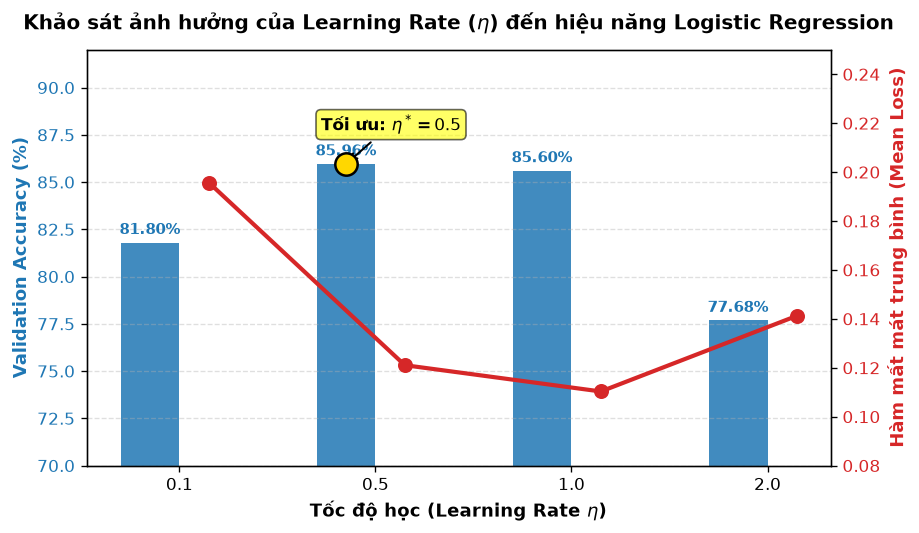

In [29]:
# (Biểu đồ 1 - Logistic): TRỰC QUAN HÓA KẾT QUẢ KHẢO SÁT SIÊU THAM SỐ
fig, ax1 = plt.subplots(figsize=(8, 4.5))

x_indices = np.arange(len(candidate_lrs))
color_acc = "#1f77b4"   
color_loss = "#d62728" 

bars = ax1.bar(x_indices - 0.15, lr_val_accs, width=0.3, color=color_acc, alpha=0.85, label="Validation Accuracy (%)")
ax1.set_xlabel(r"Tốc độ học (Learning Rate $\eta$)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Validation Accuracy (%)", color=color_acc, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_acc)
ax1.set_xticks(x_indices)
ax1.set_xticklabels([str(lr) for lr in candidate_lrs])
ax1.set_ylim(70, 92)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:.2f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha="center", va="bottom", fontsize=9, fontweight="bold", color=color_acc)

ax2 = ax1.twinx()
line = ax2.plot(x_indices + 0.15, lr_final_losses, color=color_loss, marker="o", linewidth=2.5, markersize=8, label="Mean Loss")
ax2.set_ylabel("Hàm mất mát trung bình (Mean Loss)", color=color_loss, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_loss)
ax2.set_ylim(0.08, 0.25)

ax1.scatter([x_indices[best_idx] - 0.15], [best_val_acc], color="gold", s=180, zorder=5, edgecolors="black", linewidth=1.5)
ax1.annotate(f"Tối ưu: $\eta^* = {best_lr}$",
             xy=(x_indices[best_idx] - 0.15, best_val_acc),
             xytext=(-15, 20), textcoords="offset points",
             arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
             fontweight="bold", fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.6))

plt.title("Khảo sát ảnh hưởng của Learning Rate ($\\eta$) đến hiệu năng Logistic Regression", fontsize=12, fontweight="bold", pad=12)
ax1.grid(True, linestyle="--", alpha=0.4, axis="y")

# Lưu trữ hình ảnh độc lập vào thư mục figures/
fig_path_1 = FIGURES_DIR / "2_01_logistic_tuning.png"
plt.savefig(fig_path_1, bbox_inches="tight", dpi=150)
plt.show()


---
## **5. Huấn luyện mô hình tối ưu, Theo dõi hội tụ & Trực quan hoá trọng số**

Sau khi xác định siêu tham số tối ưu $\eta^* = 0.5$, ta tiến hành:
1. Huấn luyện mô hình One-vs-Rest chính thức trên toàn bộ $50.000$ mẫu tập Train với `max_epochs = 30` để đạt độ hội tụ cực đại.
2. Trực quan hoá **Đường cong hội tụ hàm mất mát (Loss Curve)** trung bình của 10 mô hình nhị phân qua các epoch (**Biểu đồ 2**).
3. Ghép véc-tơ trọng số của 10 mô hình con thành ma trận trọng số $\mathbf{W} \in \mathbb{R}^{785 \times 10}$, tái cấu trúc thành 10 ảnh kích thước $28 \times 28$ để quan sát **Bản đồ nhiệt khuôn mẫu nhận thức 10 chữ số** (**Biểu đồ 3**).


In [30]:
# HUẤN LUYỆN MÔ HÌNH TỐI ƯU & ĐO ĐẠC THỜI GIAN
best_lr = 0.5
max_epochs = 30

print(f"--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = {best_lr}, max_epochs = {max_epochs}) ---")

# Huấn luyện mô hình chính thức và đo thời gian khớp dữ liệu 
t0 = time.perf_counter()
model_opt = OneVsRest(eta=best_lr, lam=1e-4, max_epochs=max_epochs)
model_opt.fit(X_train, y_train)
t_fit_lr = time.perf_counter() - t0

# Đo thời gian dự đoán trên các tập Train, Val, Test
t0 = time.perf_counter()
preds_train_lr = model_opt.predict(X_train)
t_pred_train_lr = time.perf_counter() - t0

t0 = time.perf_counter()
preds_val_lr = model_opt.predict(X_val)
t_pred_val_lr = time.perf_counter() - t0

t0 = time.perf_counter()
preds_test_lr = model_opt.predict(X_test)
t_pred_test_lr = time.perf_counter() - t0

# Tính toán độ chính xác Accuracy trên cả 3 tập
acc_train_lr = accuracy_score(y_train, preds_train_lr) * 100
acc_val_lr   = accuracy_score(y_val, preds_val_lr) * 100
acc_test_lr  = accuracy_score(y_test, preds_test_lr) * 100

print(f" Huấn luyện 10 bộ phân lớp hoàn tất trong : {t_fit_lr:.3f} giây")
print(f"  - Train Accuracy (50.000 mẫu) : {acc_train_lr:.2f}% | Suy luận: {t_pred_train_lr:.3f}s")
print(f"  - Val Accuracy   (10.000 mẫu) : {acc_val_lr:.2f}% | Suy luận: {t_pred_val_lr:.3f}s")
print(f"  - Test Accuracy  (10.000 mẫu) : {acc_test_lr:.2f}% | Suy luận: {t_pred_test_lr:.3f}s")


--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = 0.5, max_epochs = 30) ---
 Huấn luyện 10 bộ phân lớp hoàn tất trong : 10.703 giây
  - Train Accuracy (50.000 mẫu) : 86.00% | Suy luận: 0.168s
  - Val Accuracy   (10.000 mẫu) : 85.96% | Suy luận: 0.028s
  - Test Accuracy  (10.000 mẫu) : 86.84% | Suy luận: 0.029s


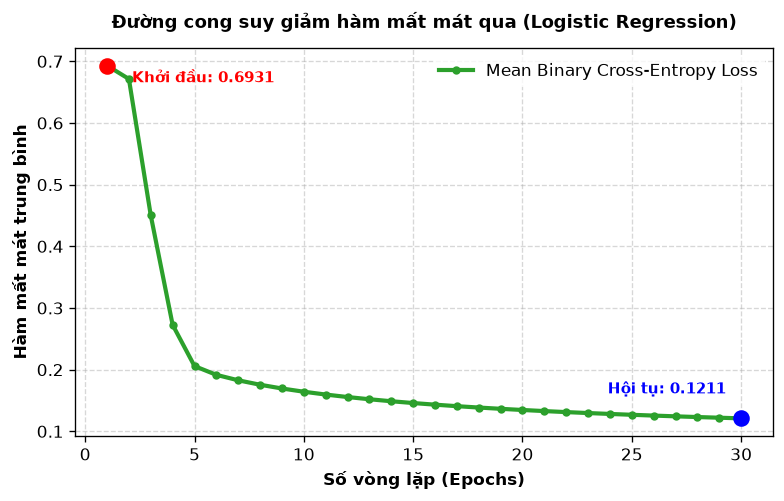

In [31]:
# (Biểu đồ 2 - Logistic): ĐƯỜNG CONG SUY GIẢM HÀM MẤT MÁT QUA CÁC EPOCH
plt.figure(figsize=(7.5, 4.2))
n_epochs = len(model_opt.loss_history_)
epochs_range = np.arange(1, n_epochs + 1)

# Vẽ đường cong hàm mất mát theo từng epoch
plt.plot(epochs_range, model_opt.loss_history_, color="#2ca02c", linewidth=2.5, marker="o", markersize=4, label="Mean Binary Cross-Entropy Loss")

plt.title("Đường cong suy giảm hàm mất mát qua (Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Số vòng lặp (Epochs)", fontsize=10, fontweight="bold")
plt.ylabel("Hàm mất mát trung bình", fontsize=10, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)

# Đánh dấu giá trị hàm mất mát khởi đầu (Epoch 1)
plt.scatter([1], [model_opt.loss_history_[0]], color="red", s=80, zorder=5)
plt.annotate(f"Khởi đầu: {model_opt.loss_history_[0]:.4f}",
             xy=(1, model_opt.loss_history_[0]),
             xytext=(15, -10), textcoords="offset points",
             fontsize=9, fontweight="bold", color="red")

# Đánh dấu giá trị hàm mất mát tại điểm hội tụ (Epoch 40)
plt.scatter([n_epochs], [model_opt.loss_history_[-1]], color="blue", s=80, zorder=5)
plt.annotate(f"Hội tụ: {model_opt.loss_history_[-1]:.4f}",
             xy=(n_epochs, model_opt.loss_history_[-1]),
             xytext=(-80, 15), textcoords="offset points",
             fontsize=9, fontweight="bold", color="blue")

plt.legend(frameon=True, facecolor="white", edgecolor="none")

fig_path_2 = FIGURES_DIR / "2_02_logistic_loss_curve.png"
plt.savefig(fig_path_2, bbox_inches="tight", dpi=150)
plt.show()


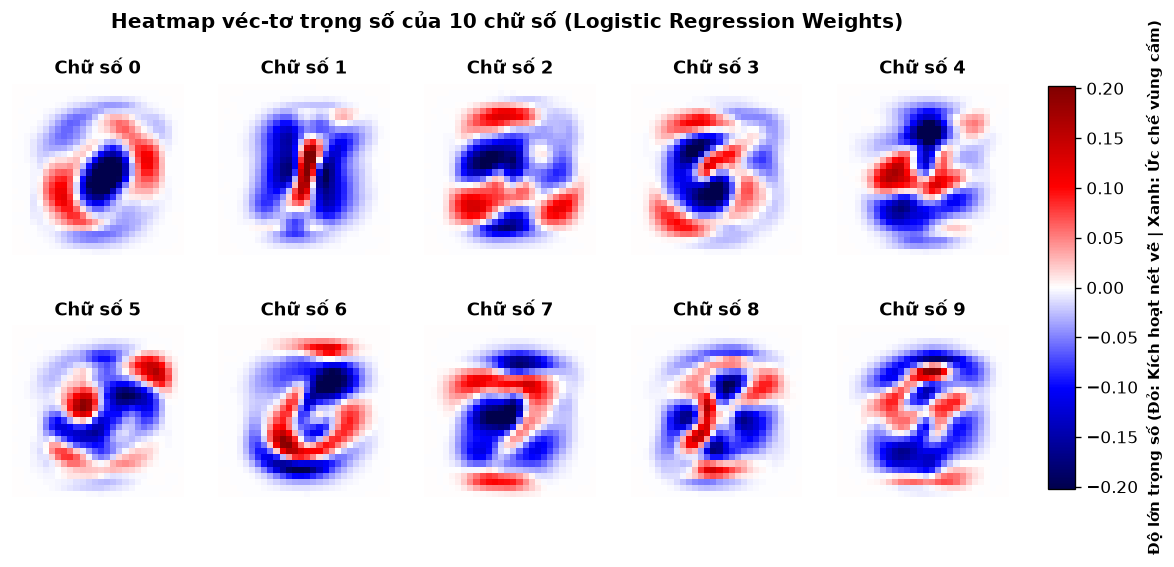

In [32]:
# (Biểu đồ 3 - Logistic): BẢN ĐỒ NHIỆT VÉC-TƠ TRỌNG SỐ W (28x28)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

weights_matrix = model_opt.W_[:-1, :]
vmax_abs = np.percentile(np.abs(weights_matrix), 99)

for c in range(10):
    w_digit = weights_matrix[:, c].reshape(28, 28)  
    im = axes[c].imshow(w_digit, cmap="seismic", vmin=-vmax_abs, vmax=vmax_abs)
    axes[c].set_title(f"Chữ số {c}", fontsize=11, fontweight="bold")
    axes[c].axis("off")

fig.subplots_adjust(right=0.88, wspace=0.2, hspace=0.2)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Độ lớn trọng số (Đỏ: Kích hoạt nét vẽ | Xanh: Ức chế vùng cấm)", fontsize=9, fontweight="bold")

plt.suptitle("Heatmap véc-tơ trọng số của 10 chữ số (Logistic Regression Weights)", fontsize=12, fontweight="bold", y=0.98)

# Lưu hình ảnh vào figures/
fig_path_3 = FIGURES_DIR / "2_03_logistic_weights.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()

---
## **6. Đối chiếu kiểm chứng với thư viện Scikit-Learn**

1. Huấn luyện mô hình `OneVsRestClassifier(LogisticRegression(solver='lbfgs', max_iter=50))` từ thư viện Scikit-Learn trên tập đối chiếu.
2. So sánh độ chính xác Test Accuracy giữa mã nguồn tự viết From Scratch và thư viện chuẩn Scikit-Learn.
3. Tính toán tỷ lệ đồng thuận dự đoán giữa hai cài đặt trên $10.000$ mẫu Test.


In [33]:
# ĐỐI CHIẾU KIỂM CHỨNG VỚI THƯ VIỆN SCIKIT-LEARN

from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# 1. Huấn luyện mô hình One-vs-Rest chuẩn của Scikit-Learn trên tập đối chiếu 10.000 mẫu
t0 = time.perf_counter()
sk_ovr = OneVsRestClassifier(SklearnLogisticRegression(C=1.0, max_iter=50, random_state=SEED, solver="lbfgs"))
sk_ovr.fit(X_train[:10000], y_train[:10000])
t_fit_sk = time.perf_counter() - t0

# 2. Đánh giá độ chính xác của Scikit-Learn trên toàn bộ 10.000 mẫu Test
preds_test_sk = sk_ovr.predict(X_test)
acc_test_sk = accuracy_score(y_test, preds_test_sk) * 100

# 3. Tính tỷ lệ đồng thuận
agreement_rate = np.mean(preds_test_lr == preds_test_sk) * 100

df_compare_lr = pd.DataFrame({
    "Phương pháp": ["Tự cài đặt (From Scratch OvR Batch GD)", "Thư viện chuẩn (Scikit-Learn OneVsRest)"],
    "Dữ liệu huấn luyện": ["Toàn bộ 50.000 mẫu", "10.000 mẫu đối chiếu"],
    "Test Accuracy (%)": [f"{acc_test_lr:.2f}%", f"{acc_test_sk:.2f}%"],
    "Thời gian huấn luyện (s)": [f"{t_fit_lr:.2f}s", f"{t_fit_sk:.2f}s"],
    "Độ chênh lệch tuyệt đối": ["-", f"{abs(acc_test_lr - acc_test_sk):.2f}%"]
})

print("--- ĐỐI CHIẾU KIỂM CHỨNG LOGISTIC REGRESSION VỚI SCIKIT-LEARN ---")
display(df_compare_lr)
print(f"Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: {agreement_rate:.2f}%")


c:\Users\Lenovo\Downloads\Pattern-Recognition_1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Lenovo\Downloads\Pattern-Recognition_1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-lear

--- ĐỐI CHIẾU KIỂM CHỨNG LOGISTIC REGRESSION VỚI SCIKIT-LEARN ---


,Phương pháp,Dữ liệu huấn luyện,Test Accuracy (%),Thời gian huấn luyện (s),Độ chênh lệch tuyệt đối
0,Tự cài đặt (From Scratch OvR Batch GD),Toàn bộ 50.000 mẫu,86.84%,10.70s,-
1,Thư viện chuẩn (Scikit-Learn OneVsRest),10.000 mẫu đối chiếu,90.59%,1.56s,3.75%


Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: 89.62%


---
## **7. Đánh giá toàn diện mô hình trên 3 tập dữ liệu (Train / Validation / Test)**


In [34]:
# TÍNH TOÁN CÁC ĐỘ ĐO TRÊN CẢ 3 TẬP
# - Bao gồm: Accuracy, Macro Precision, Macro Recall, Macro F1, Train Time, Inference Time.
def compute_lr_metrics(y_true, y_pred, t_fit, t_infer):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro Recall (%)": round(recall_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Train Time (s)": round(t_fit, 3) if t_fit > 0 else "-",
        "Inference Time (s)": round(t_infer, 3)
    }

# Lập bảng tổng hợp cho cả 3 tập dữ liệu
df_metrics_lr = pd.DataFrame([
    compute_lr_metrics(y_train, preds_train_lr, t_fit_lr, t_pred_train_lr),
    compute_lr_metrics(y_val, preds_val_lr, 0.0, t_pred_val_lr),
    compute_lr_metrics(y_test, preds_test_lr, 0.0, t_pred_test_lr)
], index=["Train (50.000 mẫu)", "Validation (10.000 mẫu)", "Test (10.000 mẫu)"])

print("--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---")
display(df_metrics_lr)


--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Train Time (s),Inference Time (s)
Train (50.000 mẫu),86.00,86.04,85.72,85.71,10.703,0.168
Validation (10.000 mẫu),85.96,85.96,85.64,85.69,-,0.028
Test (10.000 mẫu),86.84,86.87,86.58,86.55,-,0.029


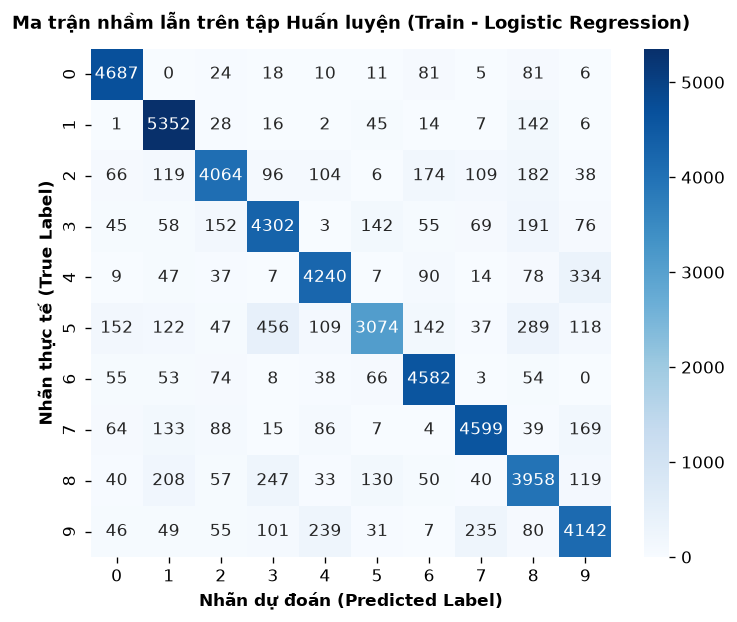

In [35]:
# (Biểu đồ 4 - Logistic): MA TRẬN NHẦM LẪN TẬP HUẤN LUYỆN (TRAIN)
cm_train_lr = confusion_matrix(y_train, preds_train_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_train_lr, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Huấn luyện (Train - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_4 = FIGURES_DIR / "2_04_logistic_confusion_train.png"
plt.savefig(fig_path_4, bbox_inches="tight", dpi=150)
plt.show()


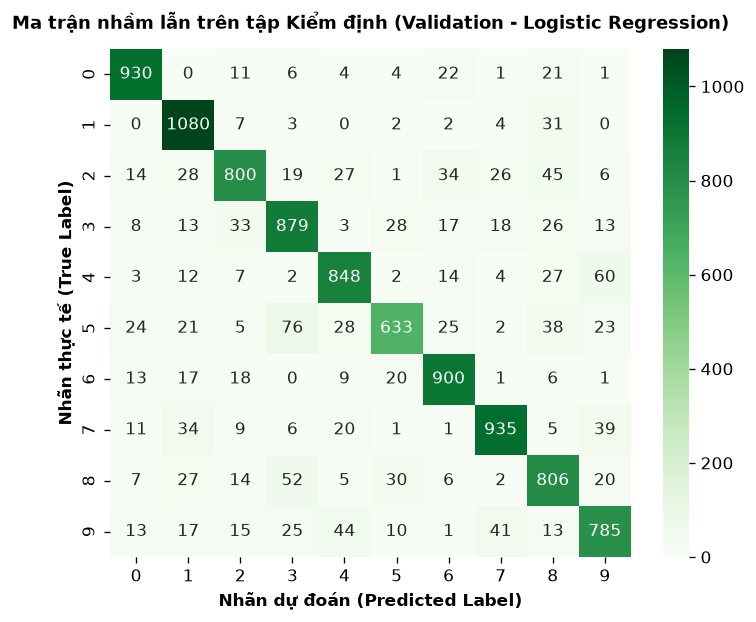

In [36]:
# (Biểu đồ 5 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM ĐỊNH (VALIDATION)

cm_val_lr = confusion_matrix(y_val, preds_val_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_val_lr, annot=True, fmt="d", cmap="Greens", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Kiểm định (Validation - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_5 = FIGURES_DIR / "2_05_logistic_confusion_val.png"
plt.savefig(fig_path_5, bbox_inches="tight", dpi=150)
plt.show()

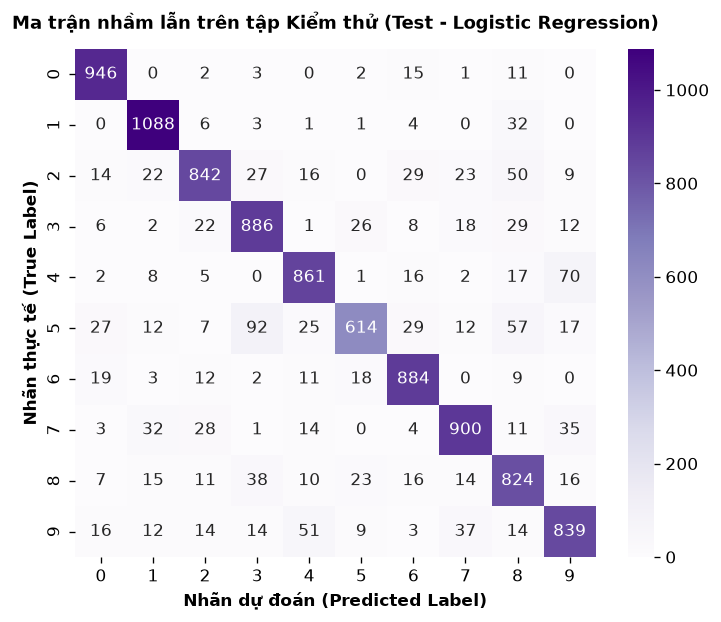

In [37]:
# (Biểu đồ 6 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM THỬ (TEST)

cm_test_lr = confusion_matrix(y_test, preds_test_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_test_lr, annot=True, fmt="d", cmap="Purples", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Kiểm thử (Test - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_6 = FIGURES_DIR / "2_06_logistic_confusion_test.png"
plt.savefig(fig_path_6, bbox_inches="tight", dpi=150)
plt.show()


In [38]:
# BẢNG PHÂN TÍCH HIỆU NĂNG CHI TIẾT TỪNG CHỮ SỐ (TEST SET)
digit_records_lr = []
total_test_samples = len(y_test)

for c in range(10):
    tp = int(cm_test_lr[c, c])                                   
    fn = int(np.sum(cm_test_lr[c, :]) - tp)                          
    fp = int(np.sum(cm_test_lr[:, c]) - tp)                        
    tn = int(total_test_samples - tp - fn - fp)                    
    
    prec = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0.0          
    rec  = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0            
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0 
    support = tp + fn                                           
    
    digit_records_lr.append({
        "Chữ số": c,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-score (%)": round(f1, 2),
        "Số mẫu (Support)": support
    })

df_digits_lr = pd.DataFrame(digit_records_lr)
print("--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---")
display(df_digits_lr)


--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---


,Chữ số,TP,FP,FN,TN,Precision (%),Recall (%),F1-score (%),Số mẫu (Support)
0,0,946,94,34,8926,90.96,96.53,93.66,980
1,1,1088,106,47,8759,91.12,95.86,93.43,1135
2,2,842,107,190,8861,88.72,81.59,85.01,1032
3,3,886,180,124,8810,83.11,87.72,85.36,1010
4,4,861,129,121,8889,86.97,87.68,87.32,982
5,5,614,80,278,9028,88.47,68.83,77.43,892
6,6,884,124,74,8918,87.70,92.28,89.93,958
7,7,900,107,128,8865,89.37,87.55,88.45,1028
8,8,824,230,150,8796,78.18,84.60,81.26,974
9,9,839,159,170,8832,84.07,83.15,83.61,1009


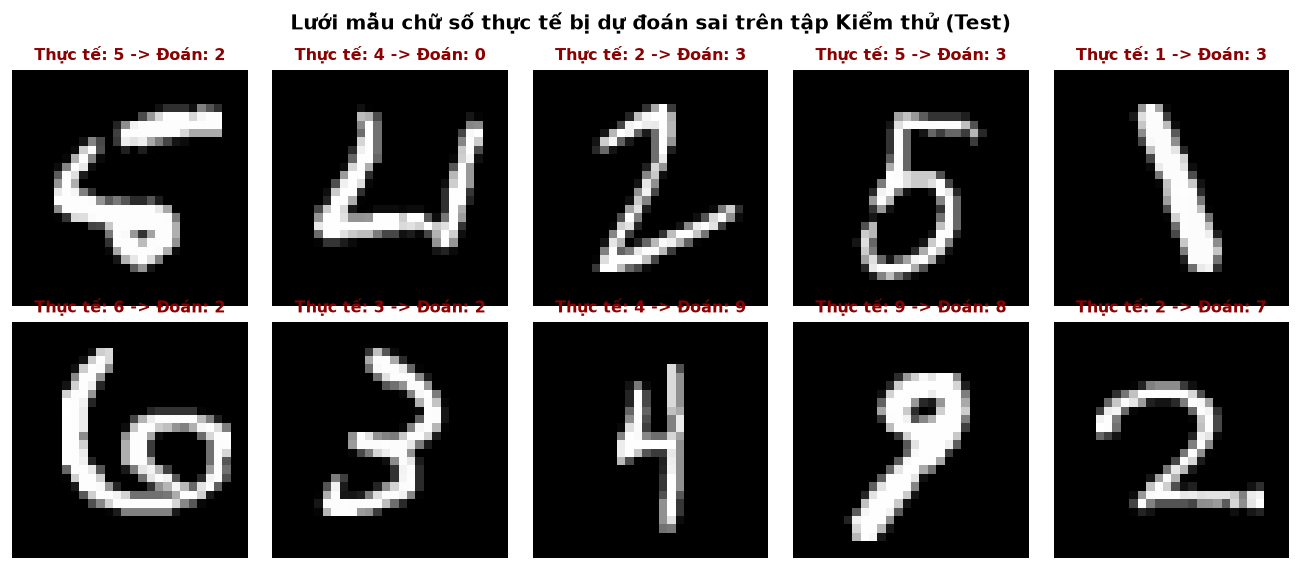

In [39]:
# Biểu đồ 7 - Logistic): LƯỚI TRỰC QUAN HÓA CÁC MẪU DỰ ĐOÁN SAI
mis_indices_lr = np.where(preds_test_lr != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for idx_plot, mis_idx in enumerate(mis_indices_lr[:10]):
    img = X_test[mis_idx].reshape(28, 28)    
    true_label = y_test[mis_idx]
    pred_label = preds_test_lr[mis_idx]
    
    axes[idx_plot].imshow(img, cmap="gray")
    axes[idx_plot].set_title(f"Thực tế: {true_label} -> Đoán: {pred_label}",
                             fontsize=9.5, fontweight="bold", color="darkred")
    axes[idx_plot].axis("off")

plt.suptitle("Lưới mẫu chữ số thực tế bị dự đoán sai trên tập Kiểm thử (Test)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()

fig_path_7 = FIGURES_DIR / "2_07_logistic_misclassified_samples.png"
plt.savefig(fig_path_7, bbox_inches="tight", dpi=150)
plt.show()


### **Nhận xét định lượng và phân tích kết quả thực nghiệm Logistic Regression**
#### **7.1. Hiệu năng tổng thể và khả năng tổng quát hóa**

Mô hình Logistic Regression tự cài đặt bằng NumPy được đánh giá với cấu hình `eta = 0.5`, `max_epochs = 30`, `lam = 1e-4`, chiến lược One-vs-Rest và `seed = 42`. Kết quả trên ba tập dữ liệu như sau:

| Tập dữ liệu | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Train (50.000 mẫu) | 86,00% | 86,04% | 85,72% | 85,71% |
| Validation (10.000 mẫu) | 85,96% | 85,96% | 85,64% | 85,69% |
| Test (10.000 mẫu) | 86,84% | 86,87% | 86,58% | 86,55% |

Thời gian huấn luyện khoảng **10,70 giây**. Thời gian dự đoán lần lượt khoảng **0,168 giây trên Train**, **0,028 giây trên Validation** và **0,029 giây trên Test**; thời gian thực tế có thể thay đổi tùy môi trường chạy.

Accuracy của Validation thấp hơn Train khoảng **0,04 điểm phần trăm**, trong khi Accuracy trên Test cao hơn Train khoảng **0,84 điểm phần trăm**. Các chỉ số trên ba tập khá gần nhau, cho thấy hiệu năng được duy trì tương đối ổn định trong lần chạy này. Tuy nhiên, chỉ riêng các con số này chưa đủ để kết luận mô hình không overfit. Tập Test nên được xem là đánh giá cuối cùng trên dữ liệu chưa dùng để lựa chọn siêu tham số.

Trên tập Test, Macro F1 đạt **86,55%**, thấp hơn Accuracy **86,84%** khoảng **0,29 điểm phần trăm**. Để đánh giá rõ hơn hiệu quả trên từng chữ số và xác định các trường hợp mô hình còn nhầm lẫn, cần xem thêm các chỉ số theo lớp và ma trận nhầm lẫn.

#### **7.2. Khả năng nhận diện từng chữ số**

Các chỉ số dưới đây được tính trên **10.000 mẫu Test**:

- **Nhận diện tốt nhất:** Chữ số **0** có F1-score cao nhất (**93,66%**), tiếp theo là chữ số **1** (**93,43%**) và chữ số **6** (**89,93%**). Mô hình nhận đúng **946/980** mẫu số 0 và **1.088/1.135** mẫu số 1.
- **Khó nhận diện nhất:** Chữ số **5** có F1-score thấp nhất (**77,43%**) và Recall thấp nhất (**68,83%**), tức mô hình nhận đúng **614/892** mẫu số 5. Precision của lớp 5 là **88,47%**.
- Chữ số **8** có Precision thấp nhất (**78,18%**), cho thấy một số mẫu thuộc lớp khác vẫn bị dự đoán nhầm thành số 8.

Nhìn chung, mô hình nhận diện tốt các chữ số **0** và **1**, nhưng vẫn bỏ sót một phần đáng kể chữ số **5** và còn nhầm lẫn giữa một số chữ số có hình dạng tương tự.

#### **7.3. Các lỗi nhầm lẫn nổi bật trên tập Test**

Ma trận nhầm lẫn trên tập Test cho thấy các cặp dự đoán sai xuất hiện nhiều nhất là:

1. **Số 5 bị dự đoán thành số 3: 92 mẫu.**
2. **Số 4 bị dự đoán thành số 9: 70 mẫu.**
3. **Số 5 bị dự đoán thành số 8: 57 mẫu.**
4. **Số 9 bị dự đoán thành số 4: 51 mẫu.**
5. **Số 2 bị dự đoán thành số 8: 50 mẫu.**

Lỗi nổi bật nhất là sự nhầm lẫn giữa **5 và 3**, phù hợp với Recall thấp hơn của lớp 5 (**68,83%**). Các nhầm lẫn giữa **4 và 9**, cũng như giữa **2 và 8**, cho thấy một số chữ số viết tay có nét hoặc hình dạng gần nhau khiến mô hình khó phân biệt.

#### **7.4. Giới hạn của Logistic Regression và hướng phát triển**

Trong cài đặt này, Logistic Regression tính điểm số từ tổ hợp tuyến tính của các pixel và xem mỗi ảnh như một vector đặc trưng. Vì vậy, mô hình chưa khai thác trực tiếp cấu trúc không gian hay quan hệ giữa các nét ở những vị trí lân cận. Hạn chế này có thể khiến mô hình khó phân biệt các chữ số viết tay có hình dạng gần nhau hoặc biến dạng.

Với cấu hình `eta = 0.5`, `max_epochs = 30` và `lam = 1e-4`, mô hình đạt Accuracy **86,84%** và Macro F1 **86,55%** trên tập Test. Đây là kết quả cải thiện so với cấu hình trước, đồng thời là mốc cơ sở để so sánh với các mô hình khác. Trong kết quả thực nghiệm hiện có, MLP đạt Test Accuracy **98,26%** và CNN đạt **98,76%**. MLP có khả năng học các quan hệ phi tuyến, còn CNN khai thác cấu trúc không gian của ảnh, phù hợp hơn với bài toán nhận diện chữ số viết tay.

Có thể tiếp tục khảo sát siêu tham số và phương pháp tối ưu cho Logistic Regression; nếu mục tiêu là nâng cao độ chính xác, có thể đối chiếu với MLP và CNN trên cùng cách chia Train/Validation/Test.

---
## **8. Đóng gói và xuất kết quả thực nghiệm**

* Xuất bảng chỉ số thực nghiệm 3 tập ra `results/2_Logistic_metrics.csv`.
* Xuất file nén checkpoint `artifacts/2_logistic_results.npz` (chứa ma trận trọng số $\mathbf{W}$, lịch sử hàm mất mát, mảng dự đoán và độ chính xác).


In [40]:
# ĐÓNG GÓI VÀ XUẤT KẾT QUẢ THỰC NGHIỆM 
# - Xuất bảng chỉ số thực nghiệm 3 tập ra results/2_Logistic_metrics.csv.

# 1. Xuất file CSV metrics 3 tập 
p_train = precision_score(y_train, preds_train_lr, average="macro", zero_division=0)
r_train = recall_score(y_train, preds_train_lr, average="macro", zero_division=0)
f1_train = f1_score(y_train, preds_train_lr, average="macro", zero_division=0)
p_val = precision_score(y_val, preds_val_lr, average="macro", zero_division=0)
r_val = recall_score(y_val, preds_val_lr, average="macro", zero_division=0)
f1_val = f1_score(y_val, preds_val_lr, average="macro", zero_division=0)
p_test = precision_score(y_test, preds_test_lr, average="macro", zero_division=0)
r_test = recall_score(y_test, preds_test_lr, average="macro", zero_division=0)
f1_test = f1_score(y_test, preds_test_lr, average="macro", zero_division=0)
records = [
    {
        "model": "LogisticRegression-NP",
        "split": "train",
        "accuracy": round(float(acc_train_lr / 100), 5),
        "precision_macro": round(float(p_train), 5),
        "recall_macro": round(float(r_train), 5),
        "f1_macro": round(float(f1_train), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_train_lr), 4),
        "n_samples": int(len(y_train)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs={max_epochs},lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "validation",
        "accuracy": round(float(acc_val_lr / 100), 5),
        "precision_macro": round(float(p_val), 5),
        "recall_macro": round(float(r_val), 5),
        "f1_macro": round(float(f1_val), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_val_lr), 4),
        "n_samples": int(len(y_val)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs={max_epochs},lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "test",
        "accuracy": round(float(acc_test_lr / 100), 5),
        "precision_macro": round(float(p_test), 5),
        "recall_macro": round(float(r_test), 5),
        "f1_macro": round(float(f1_test), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_test_lr), 4),
        "n_samples": int(len(y_test)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs={max_epochs},lam=1e-4,strategy=OneVsRest"
    }
]

df_logistic_metrics = pd.DataFrame(records)
csv_path = RESULTS_DIR / "2_Logistic_metrics.csv"
df_logistic_metrics.to_csv(csv_path, index=False)
print(f"✔ Đã lưu bảng metrics vào: '{csv_path}'")
display(df_logistic_metrics)

# 2. Xuất file nén artifacts (.npz) lưu trữ checkpoint mô hình (Không chứa predict_proba)
logreg_artifacts_path = ARTIFACTS_DIR / "2_logistic_results.npz"

W_matrix_all = np.column_stack([m.w_ for m in model_opt.models_])

np.savez_compressed(
    logreg_artifacts_path,
    W=W_matrix_all,
    losses=model_opt.loss_history_,
    preds_train=preds_train_lr,
    preds_val=preds_val_lr,
    preds_test=preds_test_lr,
    acc_train=acc_train_lr,
    acc_val=acc_val_lr,
    acc_test=acc_test_lr
)
print(f"✔ Đã lưu artifacts checkpoint vào: '{logreg_artifacts_path}'")


✔ Đã lưu bảng metrics vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition_1\results\2_Logistic_metrics.csv'


,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,LogisticRegression-NP,train,0.8600,0.86037,0.85722,0.85707,10.7028,0.1679,50000,42,"eta=0.5,max_epochs=30,lam=1e-4,strategy=OneVsRest"
1,LogisticRegression-NP,validation,0.8596,0.85963,0.85641,0.85687,10.7028,0.0284,10000,42,"eta=0.5,max_epochs=30,lam=1e-4,strategy=OneVsRest"
2,LogisticRegression-NP,test,0.8684,0.86868,0.86579,0.86546,10.7028,0.0288,10000,42,"eta=0.5,max_epochs=30,lam=1e-4,strategy=OneVsRest"


✔ Đã lưu artifacts checkpoint vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition_1\artifacts\2_logistic_results.npz'
